## Evento Evaluativo 4 - Machine Learning

Diego Alejandro Gómez Carmona

# 1. Descripción del problema

Este DataSet se basa en predecir cuales son las especies de árbol predominante en parcelas de tierra de 30x30 metros en el bosque nacional Roosevelt, las cuales se denominan como cubierta forestal dominante, y en este dataset son 7. Usando variables cartografícas y topografícas, esto permite mantener conocimiento acerca de los ecosistemas del bosque nacional sin tener que depender de expediciones que tienen altos costos y sin tener las limitaciones de las imagenes satelitales que debido al clima y resolución indicen a fallos. Esto sirve para por ejemplo prevenir incendios, conservar los hábitats, reforestación o monitorear el cambio climatico. 

Preguntas:
1. Cómo están distribuidas las 7 clases y qué tan desbalanceadas están?
2. Qué variables separan mejor los tipos de cobertura?
3. Qué relación hay entre el área silvestre y el tipo de suelo con la cobertura?
4. Qué modelo supervisado clasifica mejor y qué clases se confunden?
5. Hace falta usar todo el dataset o con una muestra es suficiente?
6. Sin usar la etiqueta, se pueden encontrar grupos y se parecen a los tipos de cobertura?

In [1]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Exploración de los datos
## Carga del dataset


In [3]:
NUMERICAS = ['Elevation', 'Aspect', 'Slope',
             'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology',
             'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon',
             'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points']
AREAS = ['Wilderness_Area_' + str(i) for i in range(1, 5)]
SUELOS = ['Soil_Type_' + str(i) for i in range(1, 41)]
VARIABLES = NUMERICAS + AREAS + SUELOS

from ucimlrepo import fetch_ucirepo

covertype = fetch_ucirepo(id=31)
df = pd.concat([covertype.data.features, covertype.data.targets], axis=1)

df.columns = df.columns.str.replace(r'(Wilderness_Area|Soil_Type)_?(\d+)', r'\1_\2', regex=True)
df = df[VARIABLES + ['Cover_Type']]
df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39,Soil_Type_40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [4]:
# nombres de las clases según covtype.info
CLASES = {1: 'Picea/Abeto', 2: 'Pino contorta', 3: 'Pino ponderosa', 4: 'Álamo/Sauce',
          5: 'Álamo temblón', 6: 'Abeto Douglas', 7: 'Krummholz'}

## 3. Preprocesamiento


El dataset al no tener nulos y que las variables categóricas ya están en formato binario, no es necesario imputar, que es llenar vacíos, o codificar, que es pasar categorías o textos a números. Solo es necesario estandarizar las columnas numéricas, haciendo que todas tengan media 0 y desviación 1, evitando que alguna columna domine solo por tener números mas grandes, como las distancias de las carreteras.
Se divide el dataset en dos partes un 80% para el entrenamiento del modelo y un 20% para las pruebas. 

Para evitar la fuga de información, el escalado se hace dentro de un Pipeline, así solo aprende la media y la desviación de los datos de entrenamiento y los datos de prueba no influyen en el modelo.

## Partición entrenamiento y prueba
80% entrenamiento y 20% prueba, estratificado por la clase.

In [5]:
from sklearn.model_selection import train_test_split

X = df[VARIABLES]
y = df['Cover_Type']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Entrenamiento:", X_train.shape, "Prueba:", X_test.shape)

Entrenamiento: (464809, 54) Prueba: (116203, 54)


## Muestra

El trabajar con las 465 mil filas que trae el dataset puede hacer que modelos como KNN tarden demasiado en ejecutar debido a la gran cantidad de datos, por eso es necesario reducir la cantidad a una muestra de 100 mil registros, para que de está manera se reduzca el tiempo de ejecución manteniendo las proporciones originales.

In [6]:
X_m, _, y_m, _ = train_test_split(X_train, y_train, train_size=100000, stratify=y_train, random_state=42)

proporciones = pd.DataFrame({
    'completo': y.value_counts(normalize=True),
    'muestra': y_m.value_counts(normalize=True),
}).sort_index() * 100
proporciones.round(3)

,completo,muestra
Cover_Type,,
1,36.461,36.460
2,48.760,48.760
3,6.154,6.154
4,0.473,0.473
5,1.634,1.634
6,2.989,2.989
7,3.530,3.530


## Selección de variables

Se hace con un a muestra de 20 mil filas por motivos de eficiencia, ya que hacer la clasificación sobre muchos registros seria un proceso muy pesado, con 20 mil registros es una cantidad suficiente para obtener el ranking de importancia rápidamente, cuando se evalúan las variables, las que mas aportan son la elevación, las áreas silvestres y las distancias. Mientras que las que menos aportan son ciertos tipos de suelo por tener muy pocos registros activos, es decir, que casi todas sus filas están en 0, por su valor binario.

Elevation                             0.455787
Wilderness_Area_4                     0.144948
Horizontal_Distance_To_Roadways       0.094216
Horizontal_Distance_To_Fire_Points    0.068821
Wilderness_Area_1                     0.066963
Soil_Type_10                          0.064780
Slope                                 0.038527
Soil_Type_39                          0.033326
Hillshade_9am                         0.032727
Soil_Type_29                          0.029660
Soil_Type_38                          0.029379
Soil_Type_4                           0.028472
Soil_Type_12                          0.024989
Soil_Type_22                          0.024479
Horizontal_Distance_To_Hydrology      0.024311
Hillshade_3pm                         0.024266
Soil_Type_2                           0.024071
Soil_Type_23                          0.022171
Soil_Type_6                           0.019071
Soil_Type_40                          0.016580
dtype: float64


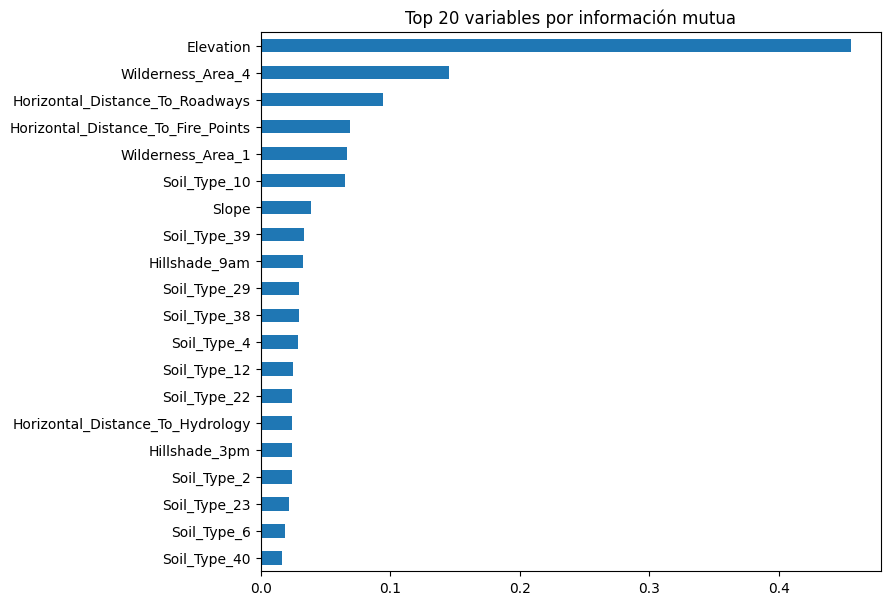

In [7]:
from sklearn.feature_selection import mutual_info_classif

X_mi, _, y_mi, _ = train_test_split(X_m, y_m, train_size=20000, stratify=y_m, random_state=42)
discretas = [col in AREAS + SUELOS for col in VARIABLES]
mi = mutual_info_classif(X_mi, y_mi, discrete_features=discretas, random_state=42)
mi = pd.Series(mi, index=VARIABLES).sort_values(ascending=False)
print(mi.head(20))

top20 = mi.head(20).index.tolist()

mi.head(20).sort_values().plot(kind='barh', figsize=(8, 7))
plt.title('Top 20 variables por información mutua')
plt.show()

## Escalado
Solo se escalan las numéricas, las binarias pasan igual.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

escalado = ColumnTransformer([('num', StandardScaler(), NUMERICAS)], remainder='passthrough')